In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import time, timedelta, datetime
import matplotlib.dates as mdates

# Load data

In [2]:
df = pd.read_csv("data/data.csv")
df.columns = ["time since boot (s)", "temp (°C)", "relative humidity (%)"]

# Describe data

In [3]:
df.describe()

,time since boot (s),temp (°C),relative humidity (%)
count,1635.000000,1635.000000,1635.000000
mean,49342.012844,15.047706,71.577982
std,28480.273102,0.259789,2.653928
min,60.000000,13.000000,65.000000
25%,24700.000000,15.000000,68.000000
50%,49342.000000,15.000000,72.000000
75%,73984.000000,15.000000,73.000000
max,98626.000000,16.000000,77.000000


## Convert to absolute time
Various experiments where conducted at different times.


|Experiment|Description|Data File|Start time|End time|
|---|---|---|---|---|
|1|25 hours first run, living room, post ventilation|data.csv|30/01/2026 at 17H21| |

In [19]:
start_date = datetime(2026, 1, 30, 17, 21)
start_date + timedelta(minutes=2)
df["date"] = pd.to_datetime([start_date + timedelta(seconds=x) for x in df["time since boot (s)"]])
df

,time since boot (s),temp (°C),relative humidity (%),date,time
0,60,16,65,2026-01-30 17:22:00,17:22
1,120,16,65,2026-01-30 17:23:00,17:23
2,181,16,65,2026-01-30 17:24:01,17:24
3,241,16,65,2026-01-30 17:25:01,17:25
4,301,15,66,2026-01-30 17:26:01,17:26
...,...,...,...,...,...
1630,98385,13,68,2026-01-31 20:40:45,20:40
1631,98445,13,67,2026-01-31 20:41:45,20:41
1632,98505,13,67,2026-01-31 20:42:45,20:42
1633,98566,13,67,2026-01-31 20:43:46,20:43


# Plotting

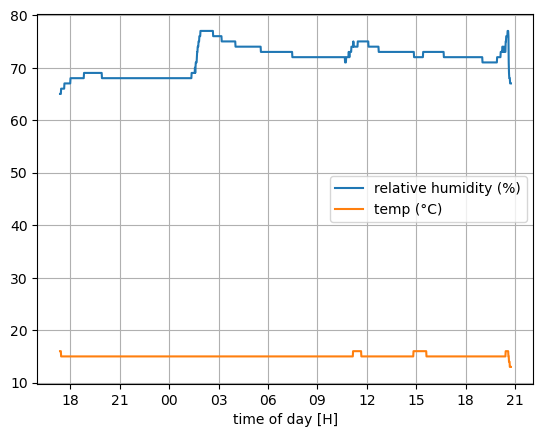

In [22]:
fig, ax= plt.subplots()
ax.plot(df.date, df["relative humidity (%)"], label="relative humidity (%)")
ax.plot(df.date, df["temp (°C)"], label="temp (°C)")
ax.legend()
myFmt = mdates.DateFormatter('%H') # formatting labels to only show hours of day
ax.xaxis.set_major_formatter(myFmt) # applying format to labels
ax.set_xlabel("time of day [H]")
ax.grid()

# Events

In [29]:
events = dict({
    datetime(2026,1,30,17,39):"coffee",
    datetime(2026,1,31,1,30):"shower",
    datetime(2026,1,31,11,7):"breakfast",
    datetime(2026,1,31,15,16):"coffee",
    datetime(2026,1,31,20,25):"dinner",
    datetime(2026,1,31,20,35):"window open",
})

Text(0.5, 1.0, 'Relative humidity / temperature readings from 30th to 31st of Jan 2026')

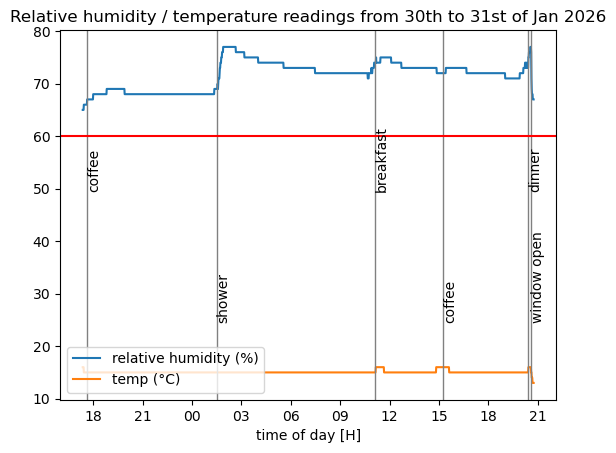

In [79]:
fig, ax= plt.subplots()
ax.plot(df.date, df["relative humidity (%)"], label="relative humidity (%)")
ax.plot(df.date, df["temp (°C)"], label="temp (°C)")
# plotting events -- start
for (num, event) in enumerate(events):
    y = 25 if num%2 else 50
    ax.axvline(event, lw=1, color="gray")
    ax.text(event, y, events[event], rotation=90)
# plotting events -- end
ax.legend(loc=3)
ax.axhline(60, color="red")
myFmt = mdates.DateFormatter('%H') # formatting labels to only show hours of day
ax.xaxis.set_major_formatter(myFmt) # applying format to labels
ax.set_xlabel("time of day [H]")
ax.set_title("Relative humidity / temperature readings from 30th to 31st of Jan 2026")
